In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
print("Libraries loaded")

Libraries loaded


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving OnlineRetail[1].csv to OnlineRetail[1].csv


In [ ]:
file_name = list(uploaded.keys())[0]

if file_name.endswith('.csv'):
    df = pd.read_csv(file_name, encoding='ISO-8859-1')
else:
    df = pd.read_excel(file_name)

print("File loaded:", file_name)
print("Shape:", df.shape)
df.head()

File loaded: OnlineRetail[1].csv
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [ ]:
df.info()
print("\nMissing values:")
print(df.isnull().sum())
print("\nBasic statistics:")
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Basic statistics:


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [ ]:
print("Rows before cleaning:", len(df))

# 1. Remove rows without CustomerID (we cannot track these customers)
df = df.dropna(subset=['CustomerID'])

# 2. Remove cancelled orders (InvoiceNo starts with 'C')
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.startswith('C')]

# 3. Remove wrong values
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# 4. Remove duplicate rows
df = df.drop_duplicates()

# 5. Fix data types (dayfirst=True because the date is day-month-year)
df['CustomerID'] = df['CustomerID'].astype(int)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], dayfirst=True)

print("Rows after cleaning:", len(df))
df.head()

Rows before cleaning: 541909
Rows after cleaning: 392692


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [ ]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print("Date range:", df['InvoiceDate'].min(), "to", df['InvoiceDate'].max())
print("Number of customers:", df['CustomerID'].nunique())
print("Number of countries:", df['Country'].nunique())
df[['InvoiceNo', 'CustomerID', 'Quantity', 'UnitPrice', 'TotalPrice']].head()

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Number of customers: 4338
Number of countries: 37


,InvoiceNo,CustomerID,Quantity,UnitPrice,TotalPrice
0,536365,17850,6,2.55,15.30
1,536365,17850,6,3.39,20.34
2,536365,17850,8,2.75,22.00
3,536365,17850,6,3.39,20.34
4,536365,17850,6,3.39,20.34


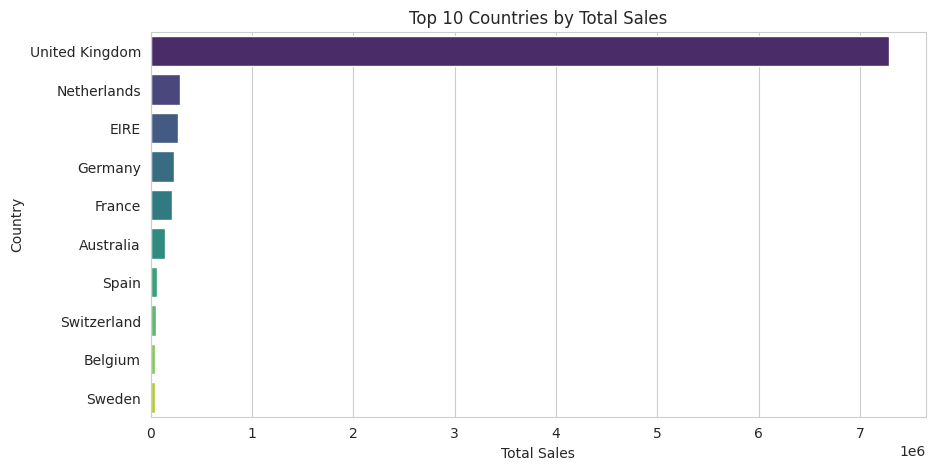

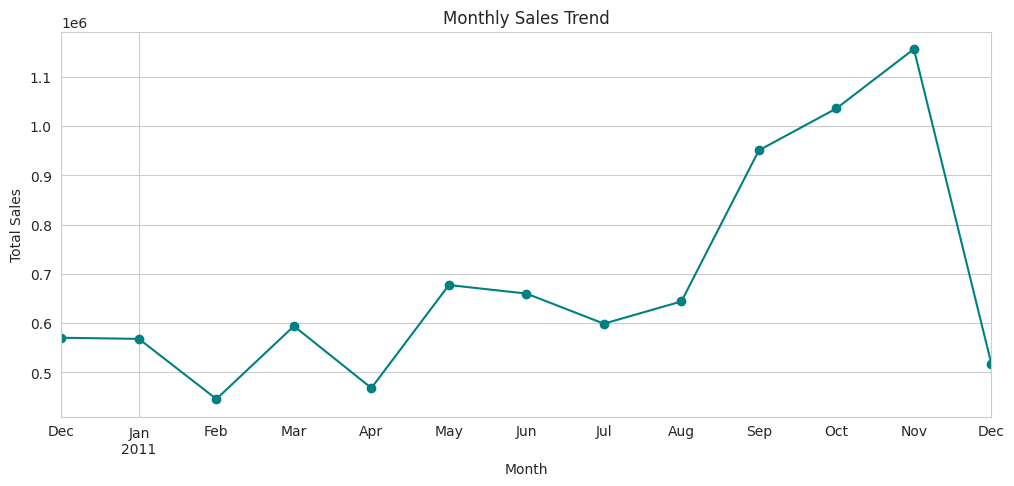

In [ ]:
# Top 10 countries by sales
country_sales = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=country_sales.values, y=country_sales.index, palette='viridis')
plt.title('Top 10 Countries by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Country')
plt.show()

# Monthly sales trend
monthly_sales = df.set_index('InvoiceDate').resample('M')['TotalPrice'].sum()

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker='o', color='teal')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.show()

In [ ]:
# Snapshot date = one day after the last purchase in the data
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency
    'InvoiceNo': 'nunique',                                    # Frequency
    'TotalPrice': 'sum'                                        # Monetary
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print("Customers in RFM table:", len(rfm))
rfm.head()

Customers in RFM table: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


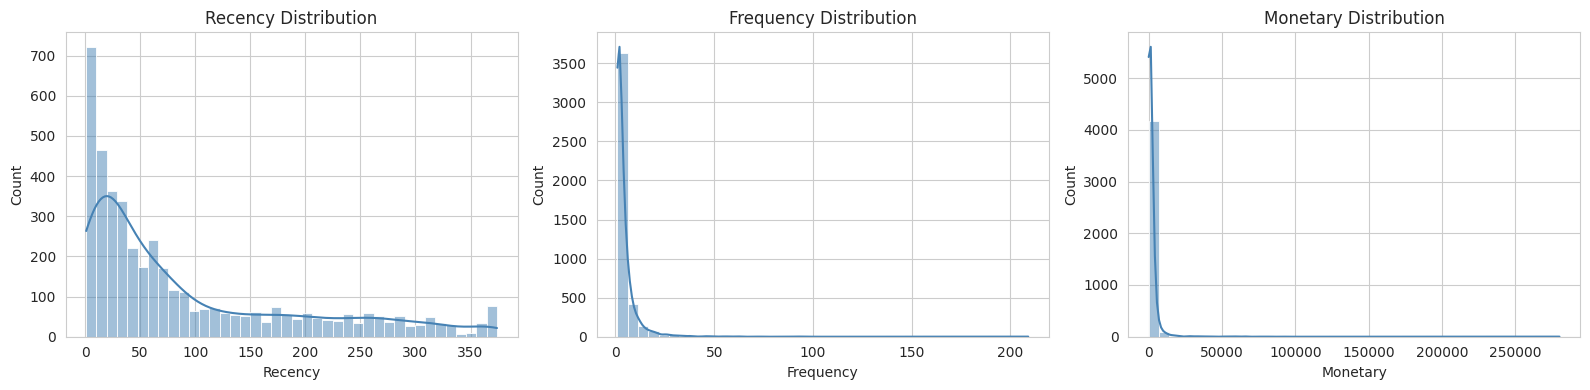

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    sns.histplot(rfm[col], bins=40, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'{col} Distribution')

plt.tight_layout()
plt.show()

rfm[['Recency', 'Frequency', 'Monetary']].describe()

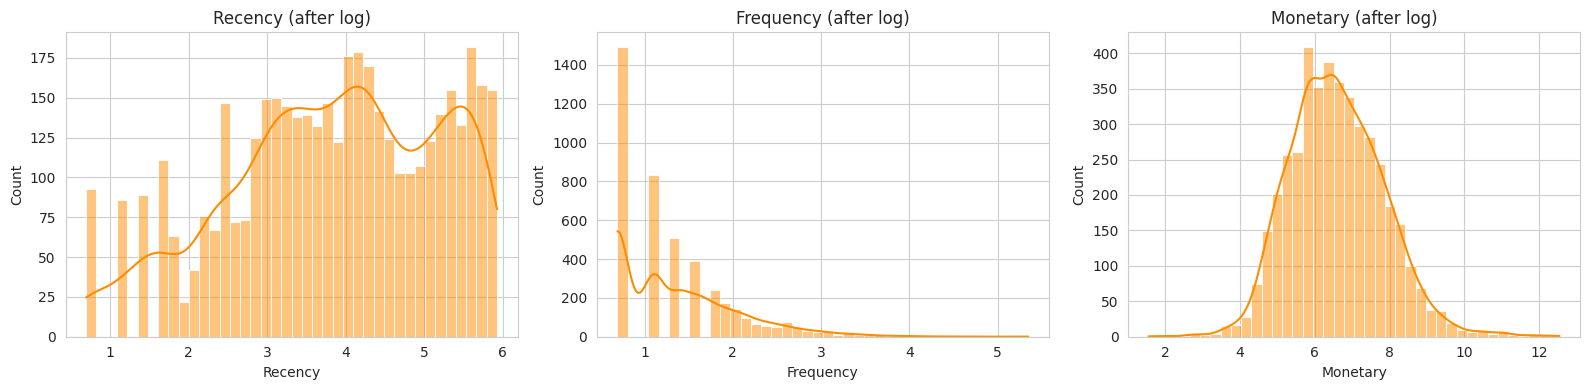

In [ ]:
# Log transform reduces the skew
rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

# Scale so all three columns have the same importance
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Check the data after the log transform
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    sns.histplot(rfm_log[col], bins=40, kde=True, ax=axes[i], color='darkorange')
    axes[i].set_title(f'{col} (after log)')
plt.tight_layout()
plt.show()

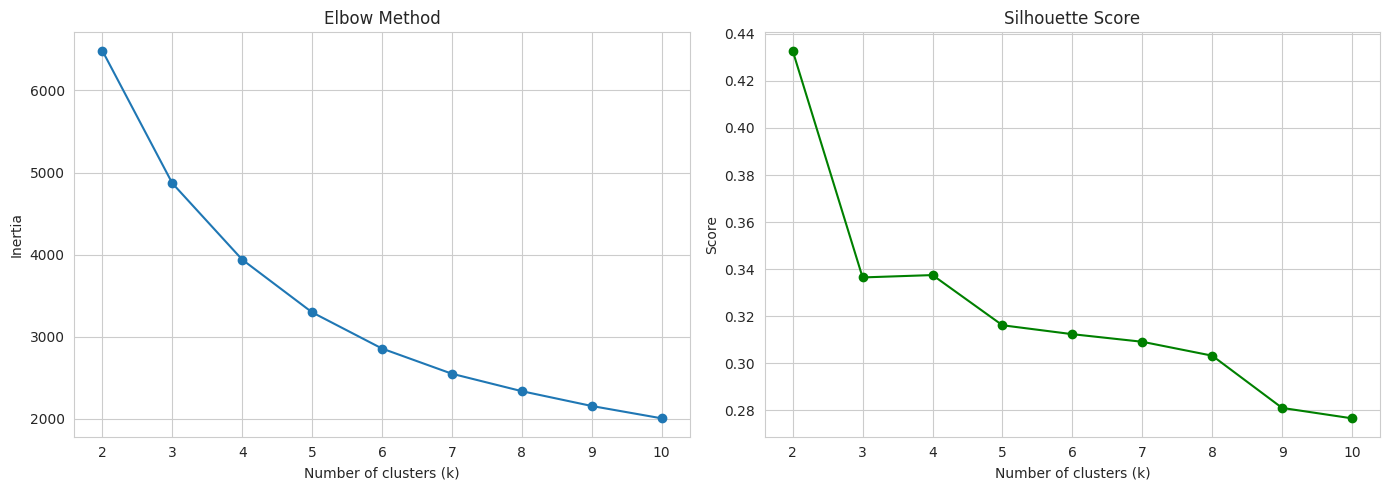

k = 2  ->  silhouette score = 0.433
k = 3  ->  silhouette score = 0.337
k = 4  ->  silhouette score = 0.338
k = 5  ->  silhouette score = 0.316
k = 6  ->  silhouette score = 0.312
k = 7  ->  silhouette score = 0.309
k = 8  ->  silhouette score = 0.303
k = 9  ->  silhouette score = 0.281
k = 10  ->  silhouette score = 0.277


In [ ]:
inertia = []
sil_scores = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertia, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_range, sil_scores, marker='o', color='green')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.show()

for k, s in zip(k_range, sil_scores):
    print(f"k = {k}  ->  silhouette score = {s:.3f}")

In [ ]:
K = 4   # you can change this after looking at the charts above

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("Silhouette score:", round(silhouette_score(rfm_scaled, rfm['Cluster']), 3))
print("\nCustomers in each cluster:")
print(rfm['Cluster'].value_counts().sort_index())

Silhouette score: 0.338

Customers in each cluster:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


In [ ]:
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'CustomerID': 'count'
}).round(1)

cluster_summary = cluster_summary.rename(columns={'CustomerID': 'Customers'})
cluster_summary

,Recency,Frequency,Monetary,Customers
Cluster,,,,
0,12.2,13.8,8088.0,713
1,181.5,1.3,341.0,1622
2,17.7,2.2,557.3,837
3,71.6,4.1,1801.8,1166


In [ ]:
# Rank clusters by average money spent (highest first)
order = cluster_summary.sort_values('Monetary', ascending=False).index.tolist()

names = ['Champions', 'Loyal Customers', 'Potential / Occasional', 'Lost / Low Value']
segment_map = {cluster: names[i] for i, cluster in enumerate(order)}

rfm['Segment'] = rfm['Cluster'].map(segment_map)

segment_summary = rfm.groupby('Segment').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'sum'],
    'CustomerID': 'count'
}).round(1)

segment_summary

Recency Frequency Monetary            CustomerID
                          mean      mean     mean        sum      count
Segment                                                                
Champions                 12.2      13.8   8088.0  5766757.1        713
Lost / Low Value         181.5       1.3    341.0   553099.8       1622
Loyal Customers           71.6       4.1   1801.8  2100873.0       1166
Potential / Occasional    17.7       2.2    557.3   466479.0        837

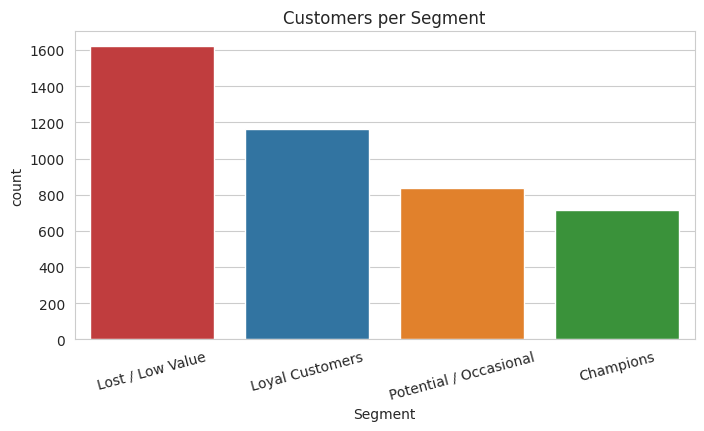

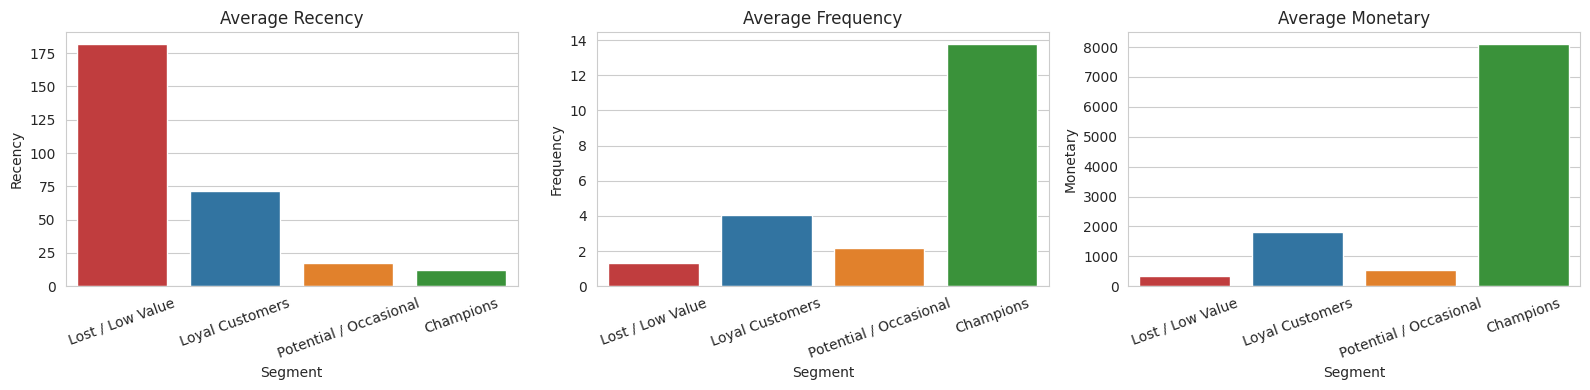

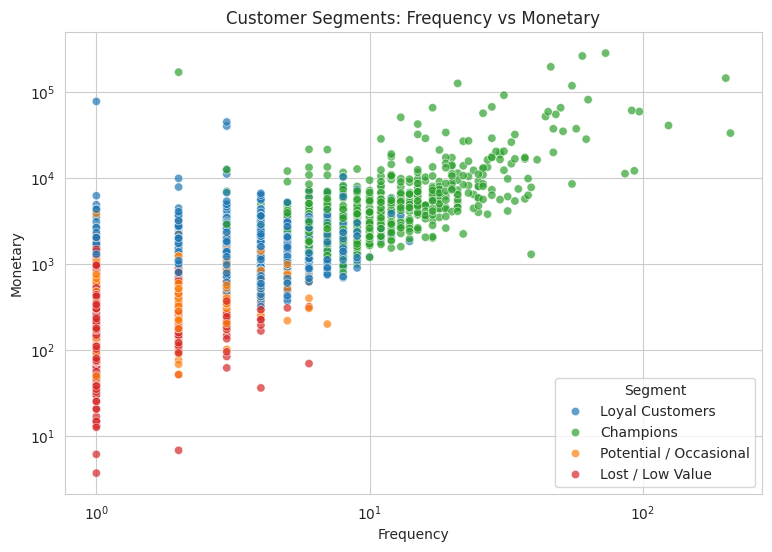

In [ ]:
palette = {'Champions': '#2ca02c', 'Loyal Customers': '#1f77b4',
           'Potential / Occasional': '#ff7f0e', 'Lost / Low Value': '#d62728'}

# 1. Number of customers in each segment
plt.figure(figsize=(8, 4))
order_names = rfm['Segment'].value_counts().index
sns.countplot(data=rfm, x='Segment', order=order_names, palette=palette)
plt.title('Customers per Segment')
plt.xticks(rotation=15)
plt.show()

# 2. Average R, F, M for each segment
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    sns.barplot(data=rfm, x='Segment', y=col, order=order_names,
                palette=palette, ax=axes[i], errorbar=None)
    axes[i].set_title(f'Average {col}')
    axes[i].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

# 3. Scatter plot
plt.figure(figsize=(9, 6))
sns.scatterplot(data=rfm, x='Frequency', y='Monetary', hue='Segment',
                palette=palette, alpha=0.7)
plt.xscale('log')
plt.yscale('log')
plt.title('Customer Segments: Frequency vs Monetary')
plt.show()

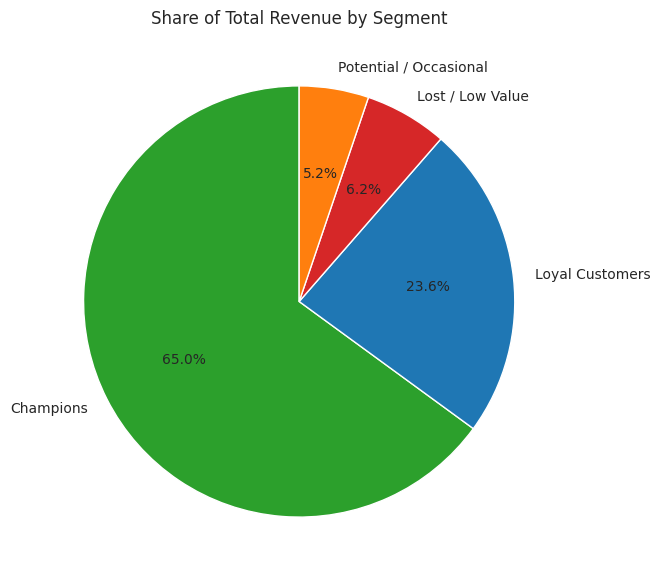

Segment
Champions                 64.9
Loyal Customers           23.6
Lost / Low Value           6.2
Potential / Occasional     5.2
Name: Monetary, dtype: float64


In [ ]:
revenue_share = rfm.groupby('Segment')['Monetary'].sum().sort_values(ascending=False)
revenue_pct = (revenue_share / revenue_share.sum() * 100).round(1)

plt.figure(figsize=(7, 7))
plt.pie(revenue_pct, labels=revenue_pct.index, autopct='%1.1f%%',
        colors=[palette[s] for s in revenue_pct.index], startangle=90)
plt.title('Share of Total Revenue by Segment')
plt.show()

print(revenue_pct)

In [ ]:
actions = {
    'Champions': 'Reward them. Give early access to new products and loyalty offers.',
    'Loyal Customers': 'Upsell higher value products. Ask for reviews and referrals.',
    'Potential / Occasional': 'Send personal offers and reminders to make them buy more often.',
    'Lost / Low Value': 'Run a win-back campaign with a discount. Do not spend too much money here.'
}

for seg, action in actions.items():
    count = (rfm['Segment'] == seg).sum()
    print(f"{seg} ({count} customers)\n   -> {action}\n")

Champions (713 customers)
   -> Reward them. Give early access to new products and loyalty offers.

Loyal Customers (1166 customers)
   -> Upsell higher value products. Ask for reviews and referrals.

Potential / Occasional (837 customers)
   -> Send personal offers and reminders to make them buy more often.

Lost / Low Value (1622 customers)
   -> Run a win-back campaign with a discount. Do not spend too much money here.



In [ ]:
rfm.to_csv('customer_segments.csv', index=False)
files.download('customer_segments.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>